# Image dataset: Decision Tree

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from models.decision_tree import DecisionTree
from utils.data import load_train
from utils.evaluation import evaluate_model, print_report, get_confusion_matrix

X, y = load_train("image")
X, y = np.asarray(X), np.asarray(y)

# 80% to train on, 20% to validate on
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, " Validation:", X_val.shape,
      " Classes:", len(np.unique(y)))

Train: (16000, 500)  Validation: (4000, 500)  Classes: 50


## Maximum depth

How many questions the tree may ask in a row. No preprocessing is used: a tree splits one feature at a time, so scaling does not change it.

,max_depth,train_accuracy,val_accuracy,val_macro_f1
0,4,0.058188,0.05825,0.036058
1,8,0.089813,0.07000,0.057228
2,16,0.177313,0.10650,0.102627
3,24,0.283313,0.10525,0.101895
4,32,0.350000,0.11250,0.112360


Kept max_depth = 32


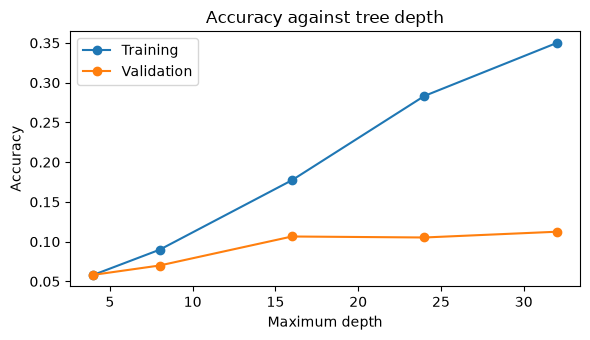

In [2]:
rows = []
best_score = 0

for max_depth in [4, 8, 16, 24, 32]:
    model = DecisionTree(
        max_depth=max_depth, min_samples_split=16, min_samples_leaf=8,
        criterion="gini",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"max_depth": max_depth, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_max_depth = metrics["val_accuracy"], max_depth

depth_table = pd.DataFrame(rows)
display(depth_table)
print("Kept max_depth =", best_max_depth)

plt.figure(figsize=(6, 3.5))
plt.plot(depth_table["max_depth"], depth_table["train_accuracy"], marker="o", label="Training")
plt.plot(depth_table["max_depth"], depth_table["val_accuracy"], marker="o", label="Validation")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Accuracy against tree depth")
plt.legend()
plt.tight_layout()
plt.show()

## Minimum samples to split

A node with fewer examples than this is not split further

In [3]:
rows = []
best_score = 0

for min_samples_split in [2, 16, 64, 256]:
    model = DecisionTree(
        max_depth=best_max_depth, min_samples_split=min_samples_split,
        min_samples_leaf=1, criterion="gini",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"min_samples_split": min_samples_split, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_min_samples_split = metrics["val_accuracy"], min_samples_split

display(pd.DataFrame(rows))
print("Kept min_samples_split =", best_min_samples_split)

,min_samples_split,train_accuracy,val_accuracy,val_macro_f1
0,2,0.660188,0.11150,0.111081
1,16,0.417625,0.11350,0.111500
2,64,0.277250,0.11775,0.115583
3,256,0.164813,0.11125,0.099789


Kept min_samples_split = 64


## Minimum samples in a leaf

Every final group must contain at least this many examples

In [4]:
rows = []
best_score = 0

for min_samples_leaf in [1, 4, 16, 64]:
    model = DecisionTree(
        max_depth=best_max_depth, min_samples_split=best_min_samples_split,
        min_samples_leaf=min_samples_leaf, criterion="gini",
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"min_samples_leaf": min_samples_leaf, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_min_samples_leaf = metrics["val_accuracy"], min_samples_leaf

display(pd.DataFrame(rows))
print("Kept min_samples_leaf =", best_min_samples_leaf)

,min_samples_leaf,train_accuracy,val_accuracy,val_macro_f1
0,1,0.277250,0.11775,0.115583
1,4,0.272750,0.11875,0.114866
2,16,0.236625,0.11600,0.112627
3,64,0.162000,0.11425,0.107554


Kept min_samples_leaf = 4


## Splitting criterion

The measure used to pick the best split: Gini impurity or entropy

In [6]:
rows = []
best_score = 0

for criterion in ["gini", "entropy"]:
    model = DecisionTree(
        max_depth=best_max_depth, min_samples_split=best_min_samples_split,
        min_samples_leaf=best_min_samples_leaf, criterion=criterion,
    )
    model.fit(X_train, y_train)

    metrics = evaluate_model(model, X_train, y_train, X_val, y_val)
    rows.append({"criterion": criterion, **metrics})

    if metrics["val_accuracy"] > best_score:
        best_score, best_criterion = metrics["val_accuracy"], criterion

display(pd.DataFrame(rows))
print("Kept criterion =", best_criterion)

,criterion,train_accuracy,val_accuracy,val_macro_f1
0,gini,0.272750,0.11875,0.114866
1,entropy,0.199313,0.10475,0.104435


Kept criterion = gini


## Final Model

The hyperparameters we reached and their scores.

max_depth: 32  min_samples_split: 64  min_samples_leaf: 4  criterion: gini
{'train_accuracy': 0.27275, 'val_accuracy': 0.11875, 'val_macro_f1': 0.11486620244775242}
              precision    recall  f1-score   support

           0       0.09      0.11      0.10        80
           1       0.14      0.07      0.10        80
           2       0.32      0.28      0.30        80
           3       0.10      0.16      0.12        80
           4       0.25      0.16      0.20        80
           5       0.24      0.42      0.30        80
           6       0.09      0.04      0.05        80
           7       0.10      0.16      0.13        80
           8       0.19      0.12      0.15        80
           9       0.06      0.05      0.05        80
          10       0.04      0.05      0.05        80
          11       0.07      0.09      0.08        80
          12       0.28      0.25      0.26        80
          13       0.15      0.17      0.16        80
          14       0.06 

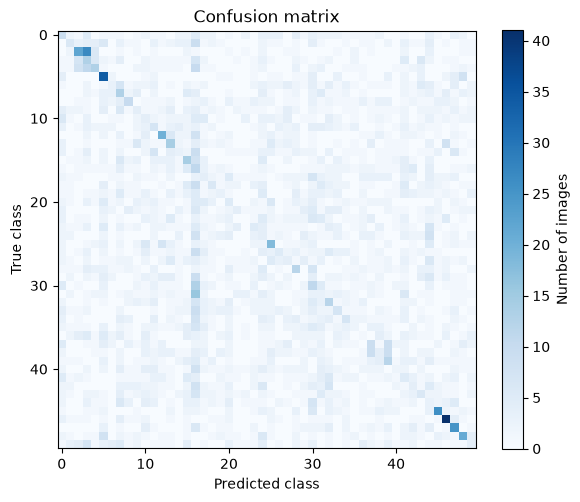

In [7]:
print("max_depth:", best_max_depth, " min_samples_split:", best_min_samples_split,
      " min_samples_leaf:", best_min_samples_leaf, " criterion:", best_criterion)

model = DecisionTree(
    max_depth=best_max_depth, min_samples_split=best_min_samples_split,
    min_samples_leaf=best_min_samples_leaf, criterion=best_criterion,
)
model.fit(X_train, y_train)

print(evaluate_model(model, X_train, y_train, X_val, y_val))

val_predictions = model.predict(X_val)
print_report(y_val, val_predictions)

# 50 classes: the confusion matrix is shown as a picture instead of a table
labels = np.unique(y_val)
matrix = get_confusion_matrix(y_val, val_predictions, labels=labels)

plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="Blues")
plt.colorbar(label="Number of images")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()